# Motor TPL pricing: walkthrough

A readable tour of the results of `python -m src.pipeline`. All logic lives in `src/` (Python) and `R/` (GLMs);
this notebook only imports those functions, re-computes a few headline numbers from the saved predictions and
shows the tables and figures. Run the pipeline first (it creates `data/processed/` and `reports/`).

In [1]:
import os
import sys
from pathlib import Path

# The project uses paths relative to its root.
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
from IPython.display import Image, display

from src import config, evaluate, features, metrics

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
tables = config.TABLE_DIR

## 1. Data and split
80/20 split by policy; the large-claim cap and loading are estimated on the training claims only.

In [2]:
display(pd.read_csv(tables / "split_summary.csv"))
display(pd.read_csv(tables / "large_loss.csv").T)

,set,policies,exposure_years,claims,frequency
0,train,542393,286905.4,21227,0.0740
1,test,135598,71438.1,5178,0.0725


,0
quantile,9.950000e-01
threshold_eur,3.496585e+04
train_claims,2.125900e+04
train_claims_above_threshold,1.070000e+02
train_incurred_eur,5.045058e+07
train_capped_eur,3.614325e+07
large_loss_loading,1.395900e+00


## 2. What the GBM found: the bonus-malus history flag

In the French bonus-malus system each claim-free year multiplies the coefficient by 0.95 (truncated, floor 0.50).
Starting from 100 only the values below are reachable without a claim; any other value below 100 implies a
recent malus. `features.add_bm_history_flag` turns this into a 0/1 rating factor.

In [3]:
print(features.claim_free_ladder())
train = pd.read_csv(config.PROCESSED_DIR / "train.csv",
                    usecols=["ClaimNb", "Exposure", "BonusMalus", "BonusMalusBand", "BMOffLadder", "CVFold"])
below = train[train["BonusMalus"] < 100]
t = below.groupby(["BonusMalusBand", "BMOffLadder"]).agg(exposure=("Exposure", "sum"), claims=("ClaimNb", "sum"))
t["frequency"] = t["claims"] / t["exposure"]
t.round(4)

[100, 95, 90, 85, 80, 76, 72, 68, 64, 60, 57, 54, 51, 50]


exposure  claims  frequency
BonusMalusBand BMOffLadder                                
50             0            180363.6334    9268     0.0514
51-59          0             20642.2959    1080     0.0523
               1             11224.3798    1351     0.1204
60-69          0             19717.7367    1339     0.0679
               1              7518.5946    1527     0.2031
70-89          0             24304.2646    2283     0.0939
               1              3708.2264     825     0.2225
90-99          0             11251.4619    1363     0.1211
               1               311.7811      95     0.3047

Inside each bonus band, drivers off the claim-free ladder have a much higher observed frequency: the band average hides this.

## 3. Frequency GLM refinement (R)
Each row is fitted on the training set; the selection uses only training criteria (quasi-Poisson LRT and BIC). Test columns are for information.

In [4]:
steps = pd.read_csv(tables / "freq_refinement_steps.csv")
steps[["model", "parameters", "bic", "lr", "lr_df", "p_value_quasi", "test_mean_poisson_deviance", "test_gini"]].round(4)

,model,parameters,bic,lr,lr_df,p_value_quasi,test_mean_poisson_deviance,test_gini
0,v1: bands (R/fit_glm.R selection),54,172326.5256,NaN,NaN,NaN,0.2364,0.2833
1,+ BM off-ladder flag,55,171119.6707,1220.0586,1.0,0.0000,0.2337,0.3047
2,"+ flag, DrivAge natural spline instead of bands",56,171066.2150,NaN,NaN,NaN,0.2336,0.3059
3,"+ flag, BonusMalus natural spline instead of b...",56,171125.6589,NaN,NaN,NaN,0.2336,0.3066
4,+ flag + DrivAgeBand:BonusMalusBand,103,171482.2269,271.2236,48.0,0.0000,0.2335,0.3070
5,+ flag + DrivAgeBand:BM100plus,63,171165.6028,59.6978,8.0,0.0000,0.2336,0.3051
6,+ flag + VehAgeBand:VehGas,58,171148.5082,10.7737,3.0,0.1071,0.2337,0.3051
7,refined: + flag + chosen interactions,55,171119.6707,1220.0586,1.0,0.0000,0.2337,0.3047


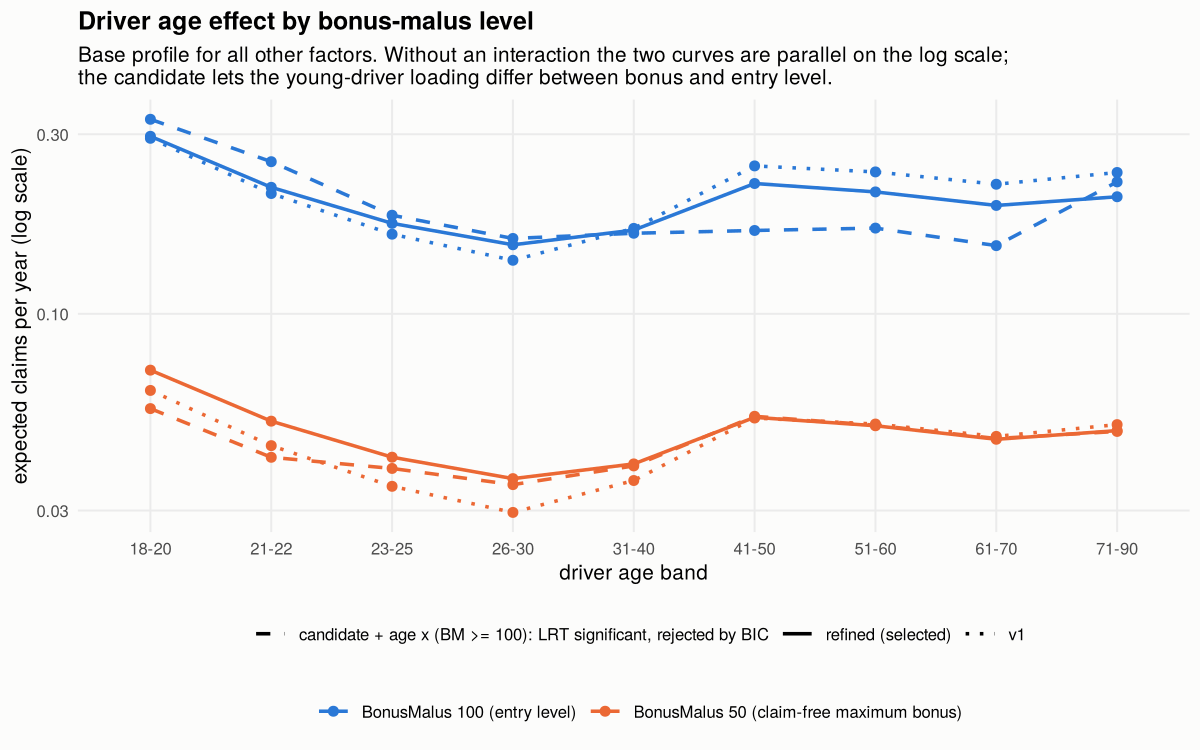

In [5]:
display(Image(config.FIG_DIR / "glm_refined_age_bm.png", width=700))

## 4. Poisson, quasi-Poisson or negative binomial?

In [6]:
display(pd.read_csv(tables / "freq_distribution_comparison.csv").round(4))
display(pd.read_csv(tables / "freq_nb_details.csv").round(4))

,model,parameters,dispersion_or_theta,theta_se,train_loglik,aic,train_fitted_over_observed,test_mean_poisson_deviance,test_mean_loglik,test_gini,se_multiplier_vs_poisson
0,Poisson,55,1.0000,NaN,-85196.7323,170503.4647,1.0000,0.2337,-0.1536,0.3047,1.0000
1,quasi-Poisson,56,1.7685,NaN,NaN,NaN,1.0000,0.2337,NaN,0.3047,1.3298
2,"negative binomial (NB2, MASS::glm.nb)",56,1.6189,0.1287,-85081.6352,170275.2704,1.0026,0.2337,-0.1534,0.3051,NaN


,metric,value
0,lr_nb_vs_poisson,230.1943
1,p_value_boundary_chibar,0.0000
2,max_abs_relativity_change_nb_vs_poisson,0.0120
3,median_abs_relativity_change_nb_vs_poisson,0.0020
4,nb_fit_seconds,25.0153
5,theta_start_poisson_means,1.6264
6,cameron_trivedi_alpha_refined,0.5241
7,cameron_trivedi_p_refined,0.0857
8,nb_implied_variance_ratio_at_mean_policy,1.0242


## 5. Test set: GLM v1, refined GLM, LightGBM
Re-computed here from the saved predictions with `src.metrics`, to check that the tables match.

In [7]:
df = evaluate.load_test_predictions()
y, e = df["ClaimNb"].to_numpy(), df["Exposure"].to_numpy()
rows = []
for col in ["freq_glm", "freq_glm_refined", "freq_glm_nb", "freq_gbm"]:
    rows.append({"model": col, "mean_poisson_deviance": metrics.mean_poisson_deviance(y, df[col].to_numpy() * e),
                 "gini": metrics.gini(y, df[col].to_numpy(), e)})
pd.DataFrame(rows).round(5)

,model,mean_poisson_deviance,gini
0,freq_glm,0.23637,0.28327
1,freq_glm_refined,0.23371,0.30475
2,freq_glm_nb,0.23373,0.30507
3,freq_gbm,0.23197,0.32024


,metric,glm_v1,glm_refined,gbm,gap_v1_to_gbm,share_closed_pct
0,mean_poisson_deviance,0.2364,0.2337,0.2320,-0.0044,60.4563
1,gini,0.2833,0.3048,0.3202,0.0370,58.0788


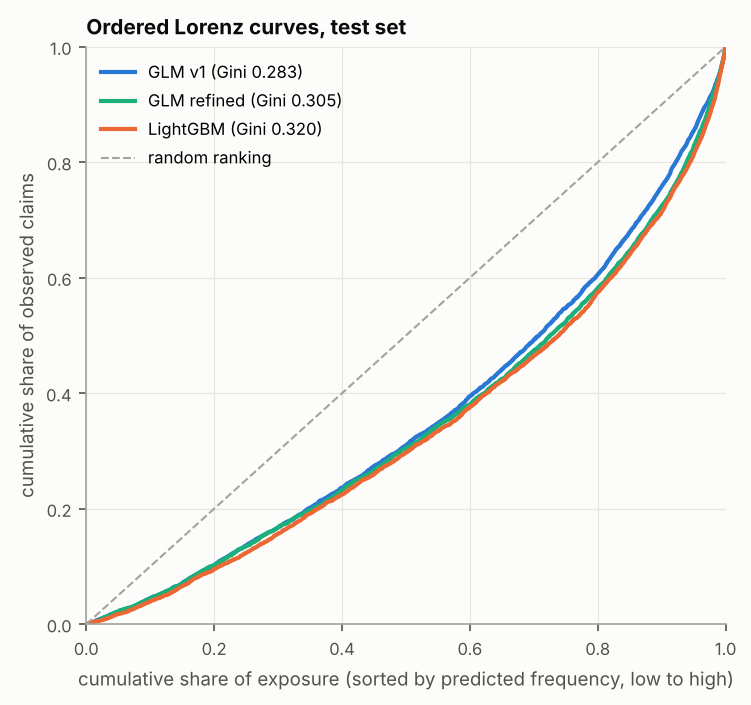

In [8]:
display(pd.read_csv(tables / "gap_closed.csv").round(4))
display(Image(config.FIG_DIR / "lorenz_curves.png", width=450))

## 6. Is the gap stable? 5-fold cross-validation and paired bootstrap

In [9]:
folds = pd.read_csv(tables / "cv_folds.csv")
display(folds.pivot(index="fold", columns="model", values="gini").round(4))
display(pd.read_csv(tables / "cv_summary.csv").round(4).T)

model,LightGBM,Poisson GLM refined,Poisson GLM v1
fold,,,
1,0.3366,0.3270,0.3045
2,0.3329,0.3202,0.2993
3,0.3170,0.3088,0.2925
4,0.3352,0.3246,0.2987
5,0.3185,0.3089,0.2951


,0,1,2
model,Poisson GLM v1,Poisson GLM refined,LightGBM
mean_poisson_deviance_mean,0.2414,0.2391,0.2376
mean_poisson_deviance_sd,0.0029,0.0029,0.003
mean_poisson_deviance_gap_LightGBM_minus_model_mean,-0.0038,-0.0015,NaN
mean_poisson_deviance_gap_LightGBM_minus_model_sd,0.0008,0.0005,NaN
folds_where_LightGBM_better_mean_poisson_deviance,5.0,5.0,NaN
gini_mean,0.298,0.3179,0.328
gini_sd,0.0046,0.0086,0.0095
gini_gap_LightGBM_minus_model_mean,0.03,0.0101,NaN
gini_gap_LightGBM_minus_model_sd,0.0058,0.0017,NaN


In [10]:
pd.read_csv(tables / "bootstrap_gini_gap.csv").round(4)

,comparison,test_gini_gap,bootstrap_sd,ci95_lower,ci95_upper,share_of_resamples_gap_positive,replicates
0,LightGBM minus Poisson GLM v1,0.0370,0.0043,0.0291,0.0461,1.0,1000
1,LightGBM minus Poisson GLM refined,0.0155,0.0038,0.0084,0.0232,1.0,1000
2,Poisson GLM refined minus Poisson GLM v1,0.0215,0.0028,0.0160,0.0268,1.0,1000


## 7. Reading

* The bonus-malus history flag, found by looking at where the GBM beats the GLM, is one extra parameter and
  closes more than half of the GLM-GBM gap on the test set.
* The remaining gap is stable across folds and its bootstrap interval excludes zero: LightGBM still ranks risks
  better. The GLM stays the tariff (readable, balanced, filable); the GBM stays a diagnostic.
* The negative binomial fits the training likelihood better but leaves relativities and test metrics practically
  unchanged, so the tariff keeps Poisson estimates with quasi-Poisson standard errors.